# NVIDIA Kitchen MJCF -> robosuite / LIBERO debug notebook

This notebook is a static-first development scaffold for adapting NVIDIA Kitchen MJCF assets into robosuite and LIBERO.

The default cells only inspect files and XML references. Cells that require `mujoco`, `robosuite`, or `libero` are optional and skip cleanly when those packages are unavailable.

## 0. Configure paths and target objects

Fill in the missing paths for your server environment. Keep the first pass small; `basket` and `glass_cup` are enough for a smoke test.

In [1]:
from pathlib import Path, PurePosixPath
import os
import re
import sys
import zipfile
import xml.etree.ElementTree as ET
from typing import Dict, Iterable, List, Optional, Tuple

# Headless NVIDIA server default: use EGL instead of GLFW/X11.
# This must be set before any `import mujoco`. Restart the Jupyter kernel if mujoco was already imported.
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("PYOPENGL_PLATFORM", "egl")

# Point this to the extracted `objects_lightwheel` directory.
# Example:
#   /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel
NVIDIA_MJCF_ROOT = Path(os.environ.get("NVIDIA_MJCF_ROOT", "~/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel")).expanduser()

# Optional. Fill this if you want to import LIBERO from a local source checkout.
# Example: /home/geyuan/code/LIBERO
LIBERO_ROOT = Path(os.environ.get("LIBERO_ROOT", "~/code/LIBERO")).expanduser()

# Keep this list short while validating the adapter pipeline.
# These names must match NVIDIA asset folder names under NVIDIA_MJCF_ROOT.
TARGET_OBJECTS = ["basket", "glass_cup"]

# LIBERO already has some object categories, such as `basket`.
# Use aliases to register NVIDIA-backed objects without overwriting built-in LIBERO categories.
# Key: NVIDIA asset folder/category. Value: LIBERO category name used in BDDL.
NVIDIA_REGISTRY_ALIASES = {"basket": "nvidia_basket"}

# Set to a concrete Path to write the generated BDDL template.
# Leave as None to only print the BDDL text.
BDDL_OUTPUT_PATH = None  # Example: Path("/home/geyuan/code/LIBERO/libero/libero/bddl_files/libero_object/nvidia_place_glass_cup_in_basket.bddl")

# Static XML check output can get noisy; set True when investigating a broken object.
SHOW_ALL_REFERENCES = False

print("NVIDIA_MJCF_ROOT:", NVIDIA_MJCF_ROOT)
print("LIBERO_ROOT:", LIBERO_ROOT)
print("TARGET_OBJECTS:", TARGET_OBJECTS)
print("NVIDIA_REGISTRY_ALIASES:", NVIDIA_REGISTRY_ALIASES)
print("MUJOCO_GL:", os.environ.get("MUJOCO_GL"))
print("PYOPENGL_PLATFORM:", os.environ.get("PYOPENGL_PLATFORM"))

NVIDIA_MJCF_ROOT: /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel
LIBERO_ROOT: /home/geyuan/code/LIBERO
TARGET_OBJECTS: ['basket', 'glass_cup']
NVIDIA_REGISTRY_ALIASES: {'basket': 'nvidia_basket'}
MUJOCO_GL: egl
PYOPENGL_PLATFORM: egl


## 1. Discover extracted assets

This cell handles the common NVIDIA archive layouts:

- `objects_lightwheel/basket/Basket001/model.xml`
- `objects_lightwheel/basket/model.xml`
- accidental double nesting such as `objects_lightwheel/whisk/whisk/Whisk001/model.xml`

In [2]:
def _category_root_candidates(category_name: str) -> List[Path]:
    """Return likely roots for one category, including accidental double nesting."""
    direct = NVIDIA_MJCF_ROOT / category_name
    return [direct, direct / category_name]


def find_category_root(category_name: str) -> Optional[Path]:
    """Pick the first root that contains at least one model.xml."""
    for candidate in _category_root_candidates(category_name):
        if candidate.exists() and any(candidate.rglob("model.xml")):
            return candidate
    return None


def discover_model_xmls(category_name: str) -> List[Path]:
    """Find all model.xml files for a category, sorted for deterministic smoke tests."""
    root = find_category_root(category_name)
    if root is None:
        return []
    return sorted(root.rglob("model.xml"))


def detect_double_nested_categories() -> List[Tuple[str, Path]]:
    """Detect folders produced by `unzip file.zip -d file`, e.g. whisk/whisk/..."""
    if not NVIDIA_MJCF_ROOT.exists():
        return []

    nested = []
    for category_dir in sorted(p for p in NVIDIA_MJCF_ROOT.iterdir() if p.is_dir()):
        double_dir = category_dir / category_dir.name
        if double_dir.is_dir() and any(double_dir.rglob("model.xml")):
            nested.append((category_dir.name, double_dir))
    return nested


def summarize_category(category_name: str) -> Dict[str, object]:
    model_xmls = discover_model_xmls(category_name)
    return {
        "category": category_name,
        "root": find_category_root(category_name),
        "num_models": len(model_xmls),
        "first_model_xml": model_xmls[0] if model_xmls else None,
    }


print("Root exists:", NVIDIA_MJCF_ROOT.exists())
if NVIDIA_MJCF_ROOT.exists():
    zip_count = len(list(NVIDIA_MJCF_ROOT.glob("*.zip")))
    dir_count = len([p for p in NVIDIA_MJCF_ROOT.iterdir() if p.is_dir()])
    print(f"Found {dir_count} extracted category dirs and {zip_count} zip files.")

nested = detect_double_nested_categories()
if nested:
    print("Double-nested extracted folders detected. The scanner can still find model.xml, but fixing the layout is cleaner:")
    for category_name, double_dir in nested[:10]:
        print(f"  {category_name}: {double_dir}")
else:
    print("No double-nested category folders detected.")

for category_name in TARGET_OBJECTS:
    print(summarize_category(category_name))

Root exists: True
Found 69 extracted category dirs and 69 zip files.
No double-nested category folders detected.
{'category': 'basket', 'root': PosixPath('/home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/basket'), 'num_models': 21, 'first_model_xml': PosixPath('/home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/basket/Basket026/model.xml')}
{'category': 'glass_cup', 'root': PosixPath('/home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/glass_cup'), 'num_models': 24, 'first_model_xml': PosixPath('/home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/glass_cup/GlassCup002/model.xml')}


## 2. Static MJCF reference checks

This does not compile physics. It only parses XML and verifies referenced mesh / texture / include files exist relative to each `model.xml`.

In [3]:
def _strip_namespace(tag: str) -> str:
    return tag.rsplit("}", 1)[-1] if "}" in tag else tag


def _resolve_mjcf_reference(model_xml: Path, raw_path: str, kind: str, compiler_dirs: Dict[str, str]) -> Path:
    """Resolve common MJCF file references relative to the current XML file."""
    raw = PurePosixPath(raw_path)
    if raw.is_absolute():
        return Path(str(raw))

    base_dir = model_xml.parent
    if kind == "mesh" and compiler_dirs.get("meshdir"):
        base_dir = model_xml.parent / compiler_dirs["meshdir"]
    elif kind == "texture" and compiler_dirs.get("texturedir"):
        base_dir = model_xml.parent / compiler_dirs["texturedir"]

    return base_dir / Path(str(raw))


def extract_mjcf_file_references(model_xml: Path) -> List[Tuple[str, str, Path]]:
    """Return `(kind, raw_file_attr, resolved_path)` for MJCF file references."""
    tree = ET.parse(model_xml)
    root = tree.getroot()

    compiler_dirs = {}
    for elem in root.iter():
        if _strip_namespace(elem.tag) == "compiler":
            compiler_dirs = {
                "meshdir": elem.attrib.get("meshdir", ""),
                "texturedir": elem.attrib.get("texturedir", ""),
            }
            break

    refs = []
    for elem in root.iter():
        tag = _strip_namespace(elem.tag)
        file_attr = elem.attrib.get("file")
        if not file_attr:
            continue

        if tag in {"mesh", "texture", "hfield", "include"}:
            kind = tag
            refs.append((kind, file_attr, _resolve_mjcf_reference(model_xml, file_attr, kind, compiler_dirs)))

    return refs


def inspect_sites(model_xml: Path) -> List[str]:
    """List named MJCF sites. LIBERO uses sites for regions such as `*_contain_region`."""
    tree = ET.parse(model_xml)
    site_names = []
    for elem in tree.getroot().iter():
        if _strip_namespace(elem.tag) == "site" and elem.attrib.get("name"):
            site_names.append(elem.attrib["name"])
    return sorted(site_names)


def static_check_model_xml(model_xml: Path) -> Dict[str, object]:
    """Parse one model.xml and check whether referenced local files are present."""
    refs = extract_mjcf_file_references(model_xml)
    missing = [(kind, raw, resolved) for kind, raw, resolved in refs if not resolved.exists()]
    return {
        "model_xml": model_xml,
        "num_references": len(refs),
        "num_missing": len(missing),
        "missing": missing,
        "sites": inspect_sites(model_xml),
    }


STATIC_CHECKS = {}
for category_name in TARGET_OBJECTS:
    model_xmls = discover_model_xmls(category_name)
    if not model_xmls:
        print(f"[{category_name}] No model.xml found.")
        continue

    # Start with the first model for smoke testing. Later you can loop over all variants.
    model_xml = model_xmls[0]
    result = static_check_model_xml(model_xml)
    STATIC_CHECKS[category_name] = result

    print(f"\n[{category_name}] {model_xml}")
    print(f"  references: {result['num_references']}")
    print(f"  missing references: {result['num_missing']}")
    print(f"  named sites: {result['sites'][:12]}")

    if SHOW_ALL_REFERENCES:
        for ref in extract_mjcf_file_references(model_xml):
            print("  ref:", ref)

    if result["missing"]:
        for kind, raw, resolved in result["missing"][:20]:
            print(f"  MISSING {kind}: {raw} -> {resolved}")


[basket] /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/basket/Basket026/model.xml
  references: 31
  missing references: 0
  named sites: []

[glass_cup] /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/glass_cup/GlassCup002/model.xml
  references: 18
  missing references: 0
  named sites: []


## 3. Optional MuJoCo native compile check

Run this only in an environment with `mujoco` installed. It verifies that MuJoCo can compile the selected `model.xml` files.

In [4]:
try:
    import mujoco
except Exception as exc:
    mujoco = None
    print("Skipping MuJoCo compile check; `import mujoco` failed:", repr(exc))

if mujoco is not None:
    for category_name in TARGET_OBJECTS:
        model_xmls = discover_model_xmls(category_name)
        if not model_xmls:
            print(f"[{category_name}] SKIP: no model.xml found")
            continue

        model_xml = model_xmls[0]
        try:
            model = mujoco.MjModel.from_xml_path(str(model_xml))
            print(
                f"[{category_name}] OK: nq={model.nq}, nv={model.nv}, "
                f"nbody={model.nbody}, ngeom={model.ngeom}, nmesh={model.nmesh}"
            )
        except Exception as exc:
            print(f"[{category_name}] FAILED to compile {model_xml}:", repr(exc))

[basket] OK: nq=0, nv=0, nbody=3, ngeom=31, nmesh=30
[glass_cup] OK: nq=0, nv=0, nbody=3, ngeom=20, nmesh=17


## 4. robosuite generic wrapper

This wrapper turns a NVIDIA MJCF `model.xml` into a robosuite `MujocoXMLObject`. It is intentionally notebook-local for debugging. After validation, move this logic into your LIBERO fork.

In [5]:
try:
    from robosuite.models.objects import MujocoXMLObject
except Exception as exc:
    MujocoXMLObject = None
    print("Skipping robosuite wrapper instantiation; `MujocoXMLObject` import failed:", repr(exc))


def select_nvidia_model_xml(category_name: str, variant_index: int = 0, model_xml_path: Optional[Path] = None) -> Path:
    """Resolve a category name to one NVIDIA model.xml path."""
    if model_xml_path is not None:
        model_xml_path = Path(model_xml_path).expanduser()
        if not model_xml_path.exists():
            raise FileNotFoundError(f"model_xml_path does not exist: {model_xml_path}")
        return model_xml_path

    model_xmls = discover_model_xmls(category_name)
    if not model_xmls:
        raise FileNotFoundError(f"No model.xml found for category: {category_name}")
    if variant_index >= len(model_xmls):
        raise IndexError(f"variant_index={variant_index} but only {len(model_xmls)} variants exist for {category_name}")
    return model_xmls[variant_index]


if MujocoXMLObject is not None:
    class NvidiaKitchenObject(MujocoXMLObject):
        """Generic robosuite object wrapper for NVIDIA Kitchen MJCF assets."""

        def __init__(
            self,
            name: str,
            category_name: str,
            variant_index: int = 0,
            model_xml_path: Optional[Path] = None,
            joints: Optional[List[Dict[str, str]]] = None,
        ):
            resolved_xml = select_nvidia_model_xml(category_name, variant_index, model_xml_path)

            # LIBERO movable objects usually need a free joint so the placement sampler can move them.
            if joints is None:
                joints = [dict(type="free", damping="0.0005")]

            super().__init__(
                str(resolved_xml),
                name=name,
                joints=joints,
                obj_type="all",
                duplicate_collision_geoms=False,
            )

            self.category_name = category_name
            self.model_xml_path = resolved_xml
            self.rotation_axis = "z"

            # Keep this shape compatible with LIBERO scanned / HOPE object wrappers.
            self.object_properties = {"vis_site_names": {}}

    print("Defined NvidiaKitchenObject.")
else:
    NvidiaKitchenObject = None
    print("NvidiaKitchenObject was not defined because robosuite is unavailable.")

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /mnt/dongxu-fs1/data-ssd/geyuan/programs/anaconda3/envs/libero/lib/python3.8/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Defined NvidiaKitchenObject.


## 5. LIBERO registry bridge

LIBERO BDDL refers to object categories such as `glass_cup`, not raw XML paths. This cell registers notebook-local classes so `get_object_fn("glass_cup")` can resolve to the NVIDIA-backed wrapper.

In [6]:
def snake_to_camel(name: str) -> str:
    """LIBERO register_object converts class names back to snake_case category names."""
    return "".join(part.capitalize() for part in name.split("_"))


if LIBERO_ROOT.exists() and str(LIBERO_ROOT) not in sys.path:
    sys.path.insert(0, str(LIBERO_ROOT))

try:
    from libero.libero.envs.base_object import register_object
    from libero.libero.envs.objects import get_object_fn
except Exception as exc:
    register_object = None
    get_object_fn = None
    print("Skipping LIBERO registry bridge; LIBERO imports failed:", repr(exc))


REGISTERED_NVIDIA_OBJECTS = {}


def registry_category_for_asset(asset_category_name: str) -> str:
    """Return the LIBERO category name for one NVIDIA asset category."""
    return NVIDIA_REGISTRY_ALIASES.get(asset_category_name, asset_category_name)


def register_nvidia_category(asset_category_name: str, registry_category_name: Optional[str] = None, variant_index: int = 0):
    """Register one NVIDIA asset category into LIBERO's object registry.

    `asset_category_name` must match the NVIDIA folder name, e.g. `basket`.
    `registry_category_name` is the LIBERO/BDDL category, e.g. `nvidia_basket` to avoid conflicts.
    """
    if register_object is None or NvidiaKitchenObject is None:
        raise RuntimeError("LIBERO and robosuite imports are required before registering objects.")

    if registry_category_name is None:
        registry_category_name = registry_category_for_asset(asset_category_name)

    # Resolve the XML from the NVIDIA asset category at registration time so broken paths fail early.
    resolved_xml = select_nvidia_model_xml(asset_category_name, variant_index=variant_index)
    class_name = snake_to_camel(registry_category_name)

    # Notebook cells are often rerun. Reuse an existing registration instead of asserting on duplicates.
    try:
        existing_cls = get_object_fn(registry_category_name)
    except Exception:
        existing_cls = None
    if existing_cls is not None:
        REGISTERED_NVIDIA_OBJECTS[registry_category_name] = existing_cls
        return existing_cls

    def __init__(self, name=registry_category_name, _registry_category_name=registry_category_name, _resolved_xml=resolved_xml):
        NvidiaKitchenObject.__init__(
            self,
            name=name,
            category_name=_registry_category_name,
            model_xml_path=_resolved_xml,
        )

    cls = type(
        class_name,
        (NvidiaKitchenObject,),
        {"__init__": __init__, "__doc__": f"NVIDIA MJCF-backed {asset_category_name}, registered as {registry_category_name}."},
    )

    # register_object returns the class and mutates LIBERO's OBJECTS_DICT.
    registered_cls = register_object(cls)
    REGISTERED_NVIDIA_OBJECTS[registry_category_name] = registered_cls
    return registered_cls


if register_object is not None and NvidiaKitchenObject is not None:
    for asset_category_name in TARGET_OBJECTS:
        registry_category_name = registry_category_for_asset(asset_category_name)
        try:
            registered_cls = register_nvidia_category(asset_category_name, registry_category_name=registry_category_name)
            resolved_fn = get_object_fn(registry_category_name)
            print(
                f"[{asset_category_name} -> {registry_category_name}] "
                f"registered as {registered_cls.__name__}; get_object_fn -> {resolved_fn}"
            )
        except Exception as exc:
            print(f"[{asset_category_name} -> {registry_category_name}] registration failed:", repr(exc))
else:
    print("Registry bridge not executed. Fill LIBERO_ROOT and run in a LIBERO/robosuite environment.")

[basket -> nvidia_basket] registered as NvidiaBasket; get_object_fn -> <class '__main__.NvidiaBasket'>
[glass_cup -> glass_cup] registered as GlassCup; get_object_fn -> <class '__main__.GlassCup'>


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## 6. Optional wrapper instantiation smoke test

This stops before creating a full robosuite/LIBERO environment. It only checks whether the registered object class can be instantiated.

In [7]:
if get_object_fn is None:
    print("Skipping object instantiation; LIBERO get_object_fn is unavailable.")
else:
    for asset_category_name in TARGET_OBJECTS:
        category_name = registry_category_for_asset(asset_category_name)
        try:
            object_cls = get_object_fn(category_name)
            obj = object_cls(name=f"{category_name}_1")
            print(f"[{asset_category_name} -> {category_name}] OK: instantiated {obj.__class__.__name__}")
            print("  category_name:", getattr(obj, "category_name", None))
            print("  model_xml_path:", getattr(obj, "model_xml_path", None))
        except Exception as exc:
            print(f"[{asset_category_name} -> {category_name}] instantiation failed:", repr(exc))

[basket -> nvidia_basket] OK: instantiated NvidiaBasket
  category_name: nvidia_basket
  model_xml_path: /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/basket/Basket026/model.xml
[glass_cup -> glass_cup] OK: instantiated GlassCup
  category_name: glass_cup
  model_xml_path: /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/glass_cup/GlassCup002/model.xml


## 7. Minimal BDDL template

This generates a first-pass BDDL file. The `In glass_cup basket_contain_region` goal only works if the basket MJCF exposes a suitable `contain_region` site or if you add one in a wrapper XML. Otherwise use this as a template and switch to a table-region goal first.

In [8]:
def _bddl_display_name(category_name: str) -> str:
    """Keep BDDL language natural even when registry names use prefixes to avoid conflicts."""
    if category_name.startswith("nvidia_"):
        category_name = category_name[len("nvidia_"):]
    return category_name.replace("_", " ")


def build_minimal_bddl(
    task_name: str = "nvidia_place_glass_cup_in_basket",
    movable_object: str = "glass_cup",
    container_object: str = "nvidia_basket",
) -> str:
    """Build a LIBERO-style BDDL template for the first adapter smoke test."""
    movable_instance = f"{movable_object}_1"
    container_instance = f"{container_object}_1"

    # LIBERO scene/problem names are resolved by the downstream LIBERO environment.
    # Keep regions conservative; tune xy bounds after rendering the tabletop scene.
    return f"""(define (problem {task_name})
  (:domain libero_tabletop_manipulation)
  (:language "place the {_bddl_display_name(movable_object)} in the {_bddl_display_name(container_object)}")

  (:regions
    (cup_init_region
      (:target table)
      (:ranges ((-0.20 -0.05 0.00 0.15)))
      (:yaw_rotation ((0.0 6.28318530718)))
    )
    (basket_init_region
      (:target table)
      (:ranges ((0.05 0.20 0.15 0.35)))
      (:yaw_rotation ((0.0 6.28318530718)))
    )
  )

  (:fixtures)

  (:objects
    {movable_instance} - {movable_object}
    {container_instance} - {container_object}
  )

  (:obj_of_interest
    {movable_instance}
    {container_instance}
  )

  (:init
    (On {movable_instance} cup_init_region)
    (On {container_instance} basket_init_region)
  )

  (:goal
    (And
      (In {movable_instance} {container_instance}_contain_region)
    )
  )
)
"""


bddl_text = build_minimal_bddl()
print(bddl_text)

basket_models = discover_model_xmls("basket")
if basket_models:
    basket_sites = inspect_sites(basket_models[0])
    contain_sites = [name for name in basket_sites if "contain" in name.lower()]
    if contain_sites:
        print("Basket candidate contain sites:", contain_sites)
    else:
        print("WARNING: No contain_region-like site found in the first basket model.xml.")
        print("Add a site named `contain_region` / `<object>_contain_region`, or temporarily change the goal predicate.")

if BDDL_OUTPUT_PATH is not None:
    BDDL_OUTPUT_PATH = Path(BDDL_OUTPUT_PATH).expanduser()
    BDDL_OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
    BDDL_OUTPUT_PATH.write_text(bddl_text)
    print("Wrote BDDL template to:", BDDL_OUTPUT_PATH)

(define (problem nvidia_place_glass_cup_in_basket)
  (:domain libero_tabletop_manipulation)
  (:language "place the glass cup in the basket")

  (:regions
    (cup_init_region
      (:target table)
      (:ranges ((-0.20 -0.05 0.00 0.15)))
      (:yaw_rotation ((0.0 6.28318530718)))
    )
    (basket_init_region
      (:target table)
      (:ranges ((0.05 0.20 0.15 0.35)))
      (:yaw_rotation ((0.0 6.28318530718)))
    )
  )

  (:fixtures)

  (:objects
    glass_cup_1 - glass_cup
    nvidia_basket_1 - nvidia_basket
  )

  (:obj_of_interest
    glass_cup_1
    nvidia_basket_1
  )

  (:init
    (On glass_cup_1 cup_init_region)
    (On nvidia_basket_1 basket_init_region)
  )

  (:goal
    (And
      (In glass_cup_1 nvidia_basket_1_contain_region)
    )
  )
)

Add a site named `contain_region` / `<object>_contain_region`, or temporarily change the goal predicate.


## 8. Optional render: place one NVIDIA object on a tabletop

This cell builds a temporary MuJoCo scene with a floor, a simple table, and one selected NVIDIA MJCF object, then saves an offscreen render. It is optional and requires `mujoco` plus a working offscreen rendering backend.

MUJOCO_GL: egl
Rendered: /home/geyuan/datasets/nvidia/PhysicalAI-Robotics-Manipulation-Objects-Kitchen-MJCF/objects_lightwheel/glass_cup/GlassCup002/model.xml
Saved image: /mnt/dongxu-fs1/data-hdd/geyuan/code/LIBERO-FT/output/nvidia_mjcf_glass_cup.png


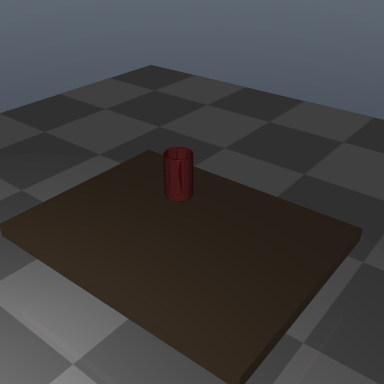

In [18]:
import copy
import tempfile
from IPython.display import Image as IPyImage, display

# Choose the NVIDIA asset category to render. This is the asset folder name, not the LIBERO alias.
RENDER_OBJECT_CATEGORY = "glass_cup"  # `glass_cup`, `basket`
RENDER_VARIANT_INDEX = 0
RENDER_OUTPUT_DIR = Path("../output").resolve()
RENDER_OUTPUT_PATH = RENDER_OUTPUT_DIR / f"nvidia_mjcf_{RENDER_OBJECT_CATEGORY}.png"

# Adjust these if the object appears too high / low or the camera framing is poor.
TABLE_TOP_Z = 0.40
OBJECT_POS = "0 0 0.43"
CAMERA_POS = "0.85 -1.00 1.15"
CAMERA_XYAXES = "0.78 0.62 0  -0.30 0.42 0.86"
RENDER_WIDTH = 384
RENDER_HEIGHT = 384


def _remove_joint_elements(elem):
    """Remove joints from copied object XML so the debug render shows a static object."""
    for child in list(elem):
        if _strip_namespace(child.tag) in {"joint", "freejoint"}:
            elem.remove(child)
        else:
            _remove_joint_elements(child)


def _resolve_all_asset_paths(model_xml: Path, root: ET.Element) -> None:
    """Rewrite mesh / texture / include file attrs to absolute paths for the temporary scene XML."""
    compiler_dirs = {}
    for elem in root.iter():
        if _strip_namespace(elem.tag) == "compiler":
            compiler_dirs = {
                "meshdir": elem.attrib.get("meshdir", ""),
                "texturedir": elem.attrib.get("texturedir", ""),
            }
            elem.attrib.pop("meshdir", None)
            elem.attrib.pop("texturedir", None)
            break

    for elem in root.iter():
        tag = _strip_namespace(elem.tag)
        file_attr = elem.attrib.get("file")
        if not file_attr or tag not in {"mesh", "texture", "hfield", "include"}:
            continue
        elem.attrib["file"] = str(_resolve_mjcf_reference(model_xml, file_attr, tag, compiler_dirs).resolve())


def _copy_xml_children(src_parent: Optional[ET.Element], dst_parent: ET.Element) -> None:
    if src_parent is None:
        return
    for child in list(src_parent):
        dst_parent.append(copy.deepcopy(child))


def build_tabletop_debug_scene_xml(model_xml: Path) -> str:
    """Create a standalone MJCF scene that displays one NVIDIA object on a simple table."""
    src_root = ET.parse(model_xml).getroot()
    _resolve_all_asset_paths(model_xml, src_root)

    src_asset = src_root.find("asset")
    src_default = src_root.find("default")
    src_worldbody = src_root.find("worldbody")
    if src_worldbody is None:
        raise ValueError(f"No <worldbody> found in {model_xml}")

    scene = ET.Element("mujoco", {"model": f"debug_{RENDER_OBJECT_CATEGORY}_tabletop"})
    ET.SubElement(scene, "compiler", {"angle": "radian"})
    ET.SubElement(scene, "option", {"gravity": "0 0 -9.81"})

    if src_default is not None:
        scene.append(copy.deepcopy(src_default))

    asset = ET.SubElement(scene, "asset")
    ET.SubElement(asset, "texture", {"name": "debug_skybox", "type": "skybox", "builtin": "gradient", "rgb1": "0.78 0.84 0.90", "rgb2": "0.05 0.07 0.10", "width": "512", "height": "512"})
    ET.SubElement(asset, "texture", {"name": "debug_floor_tex", "type": "2d", "builtin": "checker", "rgb1": "0.62 0.62 0.62", "rgb2": "0.82 0.82 0.82", "width": "256", "height": "256"})
    ET.SubElement(asset, "material", {"name": "debug_floor_mat", "texture": "debug_floor_tex", "texrepeat": "4 4", "reflectance": "0.1"})
    ET.SubElement(asset, "material", {"name": "debug_table_mat", "rgba": "0.45 0.36 0.27 1"})
    _copy_xml_children(src_asset, asset)

    worldbody = ET.SubElement(scene, "worldbody")
    ET.SubElement(worldbody, "light", {"name": "key_light", "pos": "0 -1.5 2.2", "dir": "0 0 -1", "diffuse": "0.8 0.8 0.8"})
    ET.SubElement(worldbody, "camera", {"name": "debug_camera", "pos": CAMERA_POS, "xyaxes": CAMERA_XYAXES})
    ET.SubElement(worldbody, "geom", {"name": "floor", "type": "plane", "size": "2 2 0.02", "material": "debug_floor_mat"})
    ET.SubElement(worldbody, "geom", {"name": "table", "type": "box", "pos": f"0 0 {TABLE_TOP_Z / 2:.4f}", "size": "0.50 0.38 0.025", "material": "debug_table_mat"})

    top_level_bodies = [copy.deepcopy(child) for child in list(src_worldbody) if _strip_namespace(child.tag) == "body"]
    top_level_geoms = [copy.deepcopy(child) for child in list(src_worldbody) if _strip_namespace(child.tag) == "geom"]
    if top_level_bodies:
        for body in top_level_bodies:
            _remove_joint_elements(body)
            body.attrib["pos"] = OBJECT_POS
            worldbody.append(body)
    elif top_level_geoms:
        object_body = ET.SubElement(worldbody, "body", {"name": "debug_object", "pos": OBJECT_POS})
        for geom in top_level_geoms:
            object_body.append(geom)
    else:
        raise ValueError(f"No top-level <body> or <geom> found in {model_xml}")

    return ET.tostring(scene, encoding="unicode")


try:
    import mujoco
    from PIL import Image
except Exception as exc:
    print("Skipping tabletop render; required import failed:", repr(exc))
else:
    print("MUJOCO_GL:", os.environ.get("MUJOCO_GL"))
    if os.environ.get("MUJOCO_GL") != "egl":
        print("WARNING: MUJOCO_GL is not `egl`. Restart the kernel and run the config cell before importing mujoco.")

    model_xmls = discover_model_xmls(RENDER_OBJECT_CATEGORY)
    if not model_xmls:
        print(f"No model.xml found for {RENDER_OBJECT_CATEGORY}")
    else:
        model_xml = model_xmls[RENDER_VARIANT_INDEX]
        scene_xml = build_tabletop_debug_scene_xml(model_xml)
        RENDER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        with tempfile.TemporaryDirectory(prefix="nvidia_mjcf_render_") as tmpdir:
            scene_xml_path = Path(tmpdir) / "tabletop_scene.xml"
            scene_xml_path.write_text(scene_xml)
            model = mujoco.MjModel.from_xml_path(str(scene_xml_path))
            data = mujoco.MjData(model)
            mujoco.mj_forward(model, data)

            renderer = mujoco.Renderer(model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
            try:
                renderer.update_scene(data, camera="debug_camera")
                pixels = renderer.render()
                Image.fromarray(pixels).save(RENDER_OUTPUT_PATH)
            finally:
                renderer.close()

        print("Rendered:", model_xml)
        print("Saved image:", RENDER_OUTPUT_PATH)
        display(IPyImage(filename=str(RENDER_OUTPUT_PATH)))


## 9. Next migration path

After the notebook smoke test passes, move the stable pieces into your LIBERO fork:

1. Put `NvidiaKitchenObject` into a new LIBERO object module.
2. Register a small curated set of categories first, not the full asset dataset.
3. Add or patch `site` definitions for container / surface regions needed by BDDL predicates.
4. Keep BDDL files under a separate benchmark suite until the tasks are visually and physically validated.